# Polynomial Regression

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from datetime import datetime
from sqlalchemy.dialects.postgresql import JSONB


In [2]:
# Importing the dataset and loading it into postgreSQL
engine = create_engine("postgresql+psycopg2://postgres@localhost:5432/postgres")

df = pd.read_csv("auto-mpg.csv", na_values="?")
df.to_sql("auto_mpg", engine, if_exists="replace", index=False)
pd.read_sql("select count(*) from auto_mpg", engine)

,count
0,398


In [3]:
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52.0,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84.0,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79.0,2625,18.6,82,1,ford ranger


In [4]:
df.dropna(subset=['horsepower'], inplace=True)
print(len(df))

392


In [5]:
pd.read_sql("SELECT MIN(mpg), MAX(mpg), MIN(horsepower), MAX(horsepower), MIN(weight), MAX(weight) FROM auto_mpg", engine)

,min,max,min,max,min,max
0,9.0,46.6,46.0,230.0,1613,5140


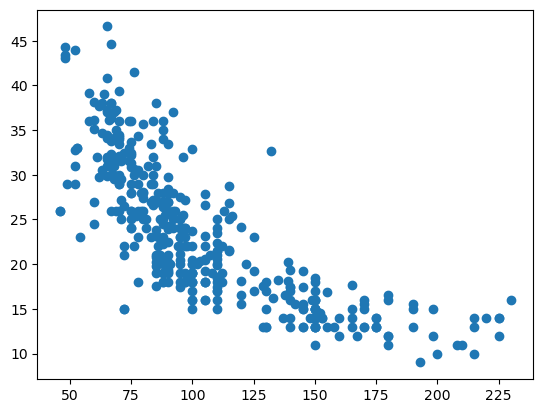

In [6]:
plt.scatter(df["horsepower"], df["mpg"])

In [7]:
df = df[[c for c in df.columns if c != "mpg"] + ["mpg"]]
df


,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name,mpg
0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu,18.0
1,8,350.0,165.0,3693,11.5,70,1,buick skylark 320,15.0
2,8,318.0,150.0,3436,11.0,70,1,plymouth satellite,18.0
3,8,304.0,150.0,3433,12.0,70,1,amc rebel sst,16.0
4,8,302.0,140.0,3449,10.5,70,1,ford torino,17.0
...,...,...,...,...,...,...,...,...,...
393,4,140.0,86.0,2790,15.6,82,1,ford mustang gl,27.0
394,4,97.0,52.0,2130,24.6,82,2,vw pickup,44.0
395,4,135.0,84.0,2295,11.6,82,1,dodge rampage,32.0
396,4,120.0,79.0,2625,18.6,82,1,ford ranger,28.0


In [8]:
X = df['horsepower']
y = df['mpg']
X = X.values.reshape(-1, 1)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

regressor = LinearRegression()
regressor.fit(X_train, y_train)
y_pred = regressor.predict(X_test)

In [10]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Root Mean Squared Error: {rmse}")
print(f"R-squared: {r2}")

Root Mean Squared Error: 4.706722545876633
R-squared: 0.5659681822256185


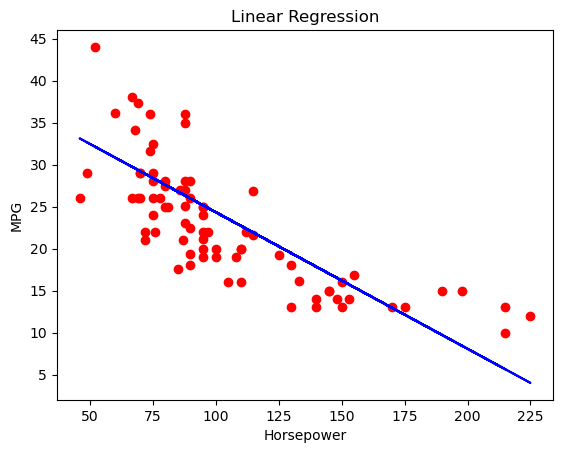

In [11]:
plt.scatter(X_test, y_test, color='red')
plt.plot(X_test, y_pred, color='blue')
plt.title('Linear Regression')
plt.xlabel('Horsepower')
plt.ylabel('MPG')
plt.show()

## Training Polynominal Regression Model

In [12]:
# train
poly_reg2 = PolynomialFeatures(degree=2)
X_poly2 = poly_reg2.fit_transform(X_train)
regressor2 = LinearRegression()
regressor2.fit(X_poly2, y_train)

# test
X_test_poly2= poly_reg2.transform(X_test)
y_pred2 = regressor2.predict(X_test_poly2)

# evaluate
rmse2 = np.sqrt(mean_squared_error(y_test, y_pred2))
mae2 = mean_absolute_error(y_test, y_pred2)
r2_2 = r2_score(y_test, y_pred2)
print(f"Degree 2 RMSE: {rmse2}")


Degree 2 RMSE: 4.291499481069267


In [13]:
# train
poly_reg3 = PolynomialFeatures(degree=3)
X_poly3 = poly_reg3.fit_transform(X_train)
regressor3 = LinearRegression()
regressor3.fit(X_poly3, y_train)

# test
X_test_poly3 = poly_reg3.transform(X_test)
y_pred3 = regressor3.predict(X_test_poly3)

# evaluate
rmse3 = np.sqrt(mean_squared_error(y_test, y_pred3))
mae3 = mean_absolute_error(y_test, y_pred3)
r2_3 = r2_score(y_test, y_pred3)
print(f"Degree 3 RMSE: {rmse3}")


Degree 3 RMSE: 4.29654130924629


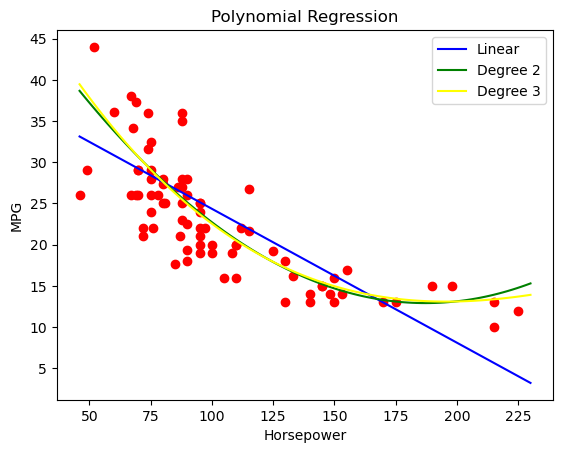

In [14]:
hp_grid = np.linspace(X_train.min(), X_train.max(), 100).reshape(-1, 1)
plt.scatter(X_test, y_test, color='red')
plt.plot(hp_grid, regressor.predict(hp_grid), color='blue', label='Linear')
plt.plot(hp_grid, regressor2.predict(poly_reg2.transform(hp_grid)), color='green', label='Degree 2')
plt.plot(hp_grid, regressor3.predict(poly_reg3.transform(hp_grid)), color='yellow', label='Degree 3')
plt.title('Polynomial Regression')
plt.xlabel('Horsepower')
plt.ylabel('MPG')

plt.savefig("fitted_curves.png")
plt.legend()
plt.show()

In [15]:
# log 2 rows to model_results table
model_results = pd.DataFrame({
    'project': 'p3_auto_mpg',
    'model': ['linear_hp', 'poly2_hp', 'poly3_hp'],
    'params': [{"feature": "horsepower", "degree": 1}, {"feature": "horsepower", "degree": 2}, {"feature": "horsepower", "degree": 3}],
    'rmse': [rmse, rmse2, rmse3], 'mae': [mae, mae2, mae3], 'r2': [r2, r2_2, r2_3],
    'run_at': datetime.now(),
})
model_results.to_sql("model_results", engine, if_exists="append", index=False, dtype={"params": JSONB})


3

In [16]:
pd.read_sql("SELECT * FROM model_results WHERE project = 'p3_auto_mpg'", engine)

,project,model,params,rmse,mae,r2,slope,run_at
0,p3_auto_mpg,linear_hp,"{'degree': 1, 'feature': 'horsepower'}",4.706723,3.782513,0.565968,None,2026-10-20 22:04:10.974758
1,p3_auto_mpg,poly2_hp,"{'degree': 2, 'feature': 'horsepower'}",4.291499,3.264281,0.639170,None,2026-10-20 22:04:10.974758
2,p3_auto_mpg,poly3_hp,"{'degree': 3, 'feature': 'horsepower'}",4.296541,3.244683,0.638322,None,2026-10-20 22:04:10.974758
3,p3_auto_mpg,poly2_hp_cv,"{'degree': 2, 'cv_rmse': 4.37, 'feature': 'hor...",4.291499,3.264281,0.639170,None,2026-10-21 10:08:50.594604
4,p3_auto_mpg,linear_hp,"{'degree': 1, 'feature': 'horsepower'}",4.706723,3.782513,0.565968,None,2026-10-21 10:12:35.656242
5,p3_auto_mpg,poly2_hp,"{'degree': 2, 'feature': 'horsepower'}",4.291499,3.264281,0.639170,None,2026-10-21 10:12:35.656242
6,p3_auto_mpg,poly3_hp,"{'degree': 3, 'feature': 'horsepower'}",4.296541,3.244683,0.638322,None,2026-10-21 10:12:35.656242
7,p3_auto_mpg,poly2_hp_cv,"{'degree': 2, 'cv_rmse': 4.37, 'feature': 'hor...",4.291499,3.264281,0.639170,None,2026-10-21 10:12:35.801694
8,p3_auto_mpg,linear_hp,"{'degree': 1, 'feature': 'horsepower'}",4.706723,3.782513,0.565968,None,2026-10-21 10:47:24.565884
9,p3_auto_mpg,poly2_hp,"{'degree': 2, 'feature': 'horsepower'}",4.291499,3.264281,0.639170,None,2026-10-21 10:47:24.565884


## Phase 3: degree sweep

In [17]:
train_rmse = []
test_rmse = []
cv_rmse = []


for d in range(1, 11):
    # train
    poly_reg = PolynomialFeatures(degree=d)
    X_poly = poly_reg.fit_transform(X_train)
    regressor = LinearRegression()
    regressor.fit(X_poly, y_train)
    y_pred = regressor.predict(X_poly)

    # joining two steps in a pipeline
    pipeline = Pipeline([
        ('poly', PolynomialFeatures(degree=d)),
        ('regressor', LinearRegression())
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_train)

    # cross validation
    cv_results = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
    cv_rmse.append(np.mean((-cv_results)))

    # evaluate
    rmse_tr = np.sqrt(mean_squared_error(y_train, y_pred))

    # test
    X_test_poly= poly_reg.transform(X_test)
    y_pred2 = regressor.predict(X_test_poly)

    # evaluate2
    rmse_te = np.sqrt(mean_squared_error(y_test, y_pred2))

    train_rmse.append(rmse_tr)
    test_rmse.append(rmse_te)

.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
.../site-pack

In [18]:
cv_rmse

[np.float64(4.936362050798875),
 np.float64(4.369998892826982),
 np.float64(4.373665327827049),
 np.float64(4.399331138248547),
 np.float64(4.379941074387802),
 np.float64(4.381598401652086),
 np.float64(4.364814020519255),
 np.float64(4.348661861506553),
 np.float64(4.374897695532608),
 np.float64(4.472499721372224)]

In [19]:
train_rmse

[np.float64(4.947238449244534),
 np.float64(4.382306891578572),
 np.float64(4.375361474747155),
 np.float64(4.373350128219759),
 np.float64(4.317873207875619),
 np.float64(4.336853613167225),
 np.float64(4.3394640243493106),
 np.float64(4.33007387780528),
 np.float64(4.344415134694591),
 np.float64(4.413031814768069)]

In [20]:
test_rmse

[np.float64(4.706722545876633),
 np.float64(4.291499481069267),
 np.float64(4.29654130924629),
 np.float64(4.274134634904978),
 np.float64(4.228120665739125),
 np.float64(4.262755094699337),
 np.float64(4.274863248721782),
 np.float64(4.278198213832839),
 np.float64(4.298184240606381),
 np.float64(4.351681292041038)]

In [21]:
for d, tr, te in zip(range(1, 11), train_rmse, test_rmse):
    print(d, round(tr, 2), round(te, 2))

1 4.95 4.71
2 4.38 4.29
3 4.38 4.3
4 4.37 4.27
5 4.32 4.23
6 4.34 4.26
7 4.34 4.27
8 4.33 4.28
9 4.34 4.3
10 4.41 4.35


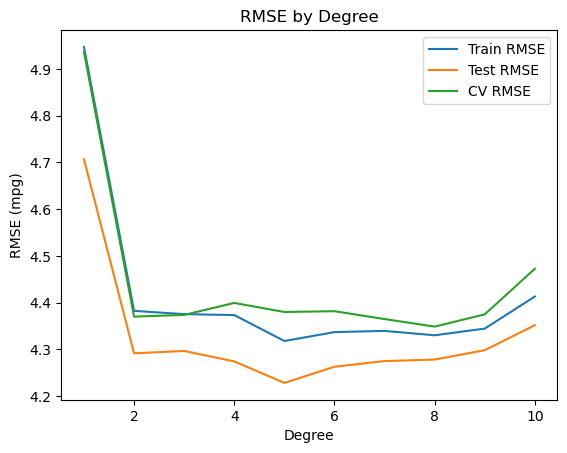

In [22]:
plt.plot(range(1, 11), train_rmse, label='Train RMSE')
plt.plot(range(1, 11), test_rmse, label='Test RMSE')
plt.plot(range(1, 11), cv_rmse, label='CV RMSE')
plt.title('RMSE by Degree')
plt.xlabel('Degree')
plt.ylabel('RMSE (mpg)')
plt.legend()
plt.savefig("rmse_by_degree.png")
plt.show()

In [23]:
pipe_hp2 = Pipeline([
    ('poly', PolynomialFeatures(degree=2)),
    ('regressor', LinearRegression())
])
pipe_hp2.fit(X_train, y_train)
y_pred_hp2 = pipe_hp2.predict(X_test)

rmse_hp2 = np.sqrt(mean_squared_error(y_test, y_pred_hp2))
mae_1 = mean_absolute_error(y_test, y_pred_hp2)
r2_1 = r2_score(y_test, y_pred_hp2)

print(f"Degree 2 RMSE: {rmse_hp2}")
print(f"Degree 2 MAE: {mae_1}")
print(f"Degree 2 R-squared: {r2_1}")



Degree 2 RMSE: 4.291499481069267
Degree 2 MAE: 3.2642808237631087
Degree 2 R-squared: 0.6391701147013311


In [24]:
model_results = pd.DataFrame({
    'project': 'p3_auto_mpg',
    'model': ['poly2_hp_cv'],
    'params': [{"feature": "horsepower", "degree": 2, "cv_rmse": 4.37}],
    'rmse': [rmse_hp2], 'mae': [mae_1], 'r2': [r2_1],
    'run_at': datetime.now(),
})
model_results.to_sql("model_results", engine, if_exists="append", index=False, dtype={"params": JSONB})

1

In [25]:
pd.read_sql("SELECT * FROM model_results WHERE project = 'p3_auto_mpg'", engine)

,project,model,params,rmse,mae,r2,slope,run_at
0,p3_auto_mpg,linear_hp,"{'degree': 1, 'feature': 'horsepower'}",4.706723,3.782513,0.565968,None,2026-10-20 22:04:10.974758
1,p3_auto_mpg,poly2_hp,"{'degree': 2, 'feature': 'horsepower'}",4.291499,3.264281,0.639170,None,2026-10-20 22:04:10.974758
2,p3_auto_mpg,poly3_hp,"{'degree': 3, 'feature': 'horsepower'}",4.296541,3.244683,0.638322,None,2026-10-20 22:04:10.974758
3,p3_auto_mpg,poly2_hp_cv,"{'degree': 2, 'cv_rmse': 4.37, 'feature': 'hor...",4.291499,3.264281,0.639170,None,2026-10-21 10:08:50.594604
4,p3_auto_mpg,linear_hp,"{'degree': 1, 'feature': 'horsepower'}",4.706723,3.782513,0.565968,None,2026-10-21 10:12:35.656242
5,p3_auto_mpg,poly2_hp,"{'degree': 2, 'feature': 'horsepower'}",4.291499,3.264281,0.639170,None,2026-10-21 10:12:35.656242
6,p3_auto_mpg,poly3_hp,"{'degree': 3, 'feature': 'horsepower'}",4.296541,3.244683,0.638322,None,2026-10-21 10:12:35.656242
7,p3_auto_mpg,poly2_hp_cv,"{'degree': 2, 'cv_rmse': 4.37, 'feature': 'hor...",4.291499,3.264281,0.639170,None,2026-10-21 10:12:35.801694
8,p3_auto_mpg,linear_hp,"{'degree': 1, 'feature': 'horsepower'}",4.706723,3.782513,0.565968,None,2026-10-21 10:47:24.565884
9,p3_auto_mpg,poly2_hp,"{'degree': 2, 'feature': 'horsepower'}",4.291499,3.264281,0.639170,None,2026-10-21 10:47:24.565884


In [26]:
df1 = df.copy()

df1 = pd.get_dummies(df1, columns=["origin"], drop_first=True)

df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 392 entries, 0 to 397
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   cylinders     392 non-null    int64  
 1   displacement  392 non-null    float64
 2   horsepower    392 non-null    float64
 3   weight        392 non-null    int64  
 4   acceleration  392 non-null    float64
 5   model year    392 non-null    int64  
 6   car name      392 non-null    object 
 7   mpg           392 non-null    float64
 8   origin_2      392 non-null    bool   
 9   origin_3      392 non-null    bool   
dtypes: bool(2), float64(4), int64(3), object(1)
memory usage: 28.3+ KB


In [27]:
X = df1.drop(columns=["cylinders", "acceleration", "car name", "mpg"])
y = df1["mpg"]

In [28]:
X_train1, X_test1, y_train1, y_test1 = train_test_split(X, y, test_size=0.2, random_state=42)

In [29]:
X_test1.shape

(79, 6)

In [30]:
lin_reg = LinearRegression()
lin_reg.fit(X_train1, y_train1)
y_pred1 = lin_reg.predict(X_test1)

rmse_1 = np.sqrt(mean_squared_error(y_test1, y_pred1))
mae_1 = mean_absolute_error(y_test1, y_pred1)
r2_1 = r2_score(y_test1, y_pred1)

print(f"Linear Regression RMSE: {rmse_1}")
print(f"Linear Regression MAE: {mae_1}")
print(f"Linear Regression R-squared: {r2_1}")

Linear Regression RMSE: 3.293446147679744
Linear Regression MAE: 2.4806470267097773
Linear Regression R-squared: 0.787486998792862


In [31]:
pipe_poly_m = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2)),
    ('regressor', LinearRegression())
])

pipe_poly_m.fit(X_train1, y_train1)
y_pred_poly_m = pipe_poly_m.predict(X_test1)
rmse_poly_m = np.sqrt(mean_squared_error(y_test1, y_pred_poly_m))
mae_poly_m = mean_absolute_error(y_test1, y_pred_poly_m)
r2_poly_m = r2_score(y_test1, y_pred_poly_m)



.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
.../site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
